<a href="https://colab.research.google.com/github/Mhamuda/CSEM2151-Computer_Vision/blob/main/Assignment10_Image_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Install required libraries

In [ ]:
!pip -q install segmentation-models-pytorch transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.8 MB/s eta 0:00:00


#Import libraries

In [ ]:
import os
import random
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

import torchvision
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet

import segmentation_models_pytorch as smp

from transformers import SegformerForSemanticSegmentation

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
GPU: Tesla T4


#Mount google drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


#Create project folders

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment10_Image_Segmentation"

RESULTS_DIR = os.path.join(PROJECT_DIR, "Results")
MODEL_DIR = os.path.join(PROJECT_DIR, "Saved_Models")

LEARNING_CURVE_DIR = os.path.join(RESULTS_DIR, "Learning_Curves")
CONFUSION_DIR = os.path.join(RESULTS_DIR, "Confusion_Matrices")
PREDICTION_DIR = os.path.join(RESULTS_DIR, "Predictions")
COMPARISON_DIR = os.path.join(RESULTS_DIR, "Comparison")
SAMPLE_DIR = os.path.join(RESULTS_DIR, "Dataset_Samples")

TASK4_DIR = os.path.join(PROJECT_DIR, "Task4_Self_Captured")

for folder in [
    PROJECT_DIR,
    RESULTS_DIR,
    MODEL_DIR,
    LEARNING_CURVE_DIR,
    CONFUSION_DIR,
    PREDICTION_DIR,
    COMPARISON_DIR,
    SAMPLE_DIR,
    TASK4_DIR
]:
    os.makedirs(folder, exist_ok=True)

print("Project folder:")
print(PROJECT_DIR)

Project folder:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment10_Image_Segmentation


#Reproducibility

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

Device: cuda


#Download Oxford-IIIT Pet dataset

In [ ]:
DATA_ROOT = os.path.join(PROJECT_DIR, "Dataset")

trainval_raw = OxfordIIITPet(
    root=DATA_ROOT,
    split="trainval",
    target_types="segmentation",
    download=True
)

test_raw = OxfordIIITPet(
    root=DATA_ROOT,
    split="test",
    target_types="segmentation",
    download=True
)

print("TrainVal images:", len(trainval_raw))
print("Test images:", len(test_raw))
print("Total images:", len(trainval_raw) + len(test_raw))

TrainVal images: 3680
Test images: 3669
Total images: 7349


#Assignment settings

In [ ]:
IMAGE_SIZE = 128

BATCH_SIZE = 16

EPOCHS = 10

LEARNING_RATE = 0.0001

NUM_CLASSES = 1

NUM_WORKERS = 2

print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)

Image size: 128
Batch size: 16
Epochs: 10
Learning rate: 0.0001


#Image and mask preprocessing

In [ ]:
class SegmentationTransform:
    def __init__(self, train=False):
        self.train = train

        self.resize = transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=Image.BILINEAR
        )

        self.mask_resize = transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=Image.NEAREST
        )

        self.image_to_tensor = transforms.ToTensor()

        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    def __call__(self, image, mask):

        if self.train:

            if random.random() < 0.5:
                image = image.transpose(Image.FLIP_LEFT_RIGHT)
                mask = mask.transpose(Image.FLIP_LEFT_RIGHT)

            if random.random() < 0.5:
                image = image.transpose(Image.FLIP_TOP_BOTTOM)
                mask = mask.transpose(Image.FLIP_TOP_BOTTOM)

        image = self.resize(image)
        mask = self.mask_resize(mask)

        image = self.image_to_tensor(image)
        image = self.normalize(image)

        mask = np.array(mask)

        # Oxford Pet trimap:
        # 1 = foreground
        # 2 = background
        # 3 = boundary
        mask = np.where(mask == 2, 0, 1)

        mask = torch.tensor(mask, dtype=torch.float32)
        mask = mask.unsqueeze(0)

        return image, mask

#Dataset class

In [ ]:
class PetSegmentationDataset(Dataset):

    def __init__(self, root, split, train=False):
        self.dataset = OxfordIIITPet(
            root=root,
            split=split,
            target_types="segmentation",
            download=False
        )

        self.transform = SegmentationTransform(train=train)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):

        image, mask = self.dataset[idx]

        image, mask = self.transform(image, mask)

        return image, mask

#Create fixed train/validation/test split

In [ ]:
indices = np.arange(len(trainval_raw))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED
)

print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))
print("Testing images:", len(test_raw))

Training images: 2944
Validation images: 736
Testing images: 3669


#Create datasets

In [ ]:
train_dataset_full = PetSegmentationDataset(
    DATA_ROOT,
    "trainval",
    train=True
)

val_dataset_full = PetSegmentationDataset(
    DATA_ROOT,
    "trainval",
    train=False
)

test_dataset = PetSegmentationDataset(
    DATA_ROOT,
    "test",
    train=False
)

train_dataset = Subset(
    train_dataset_full,
    train_indices
)

val_dataset = Subset(
    val_dataset_full,
    val_indices
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 2944
Validation: 736
Test: 3669


#DataLoaders

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("DataLoaders created.")

DataLoaders created.


#Show sample images and masks

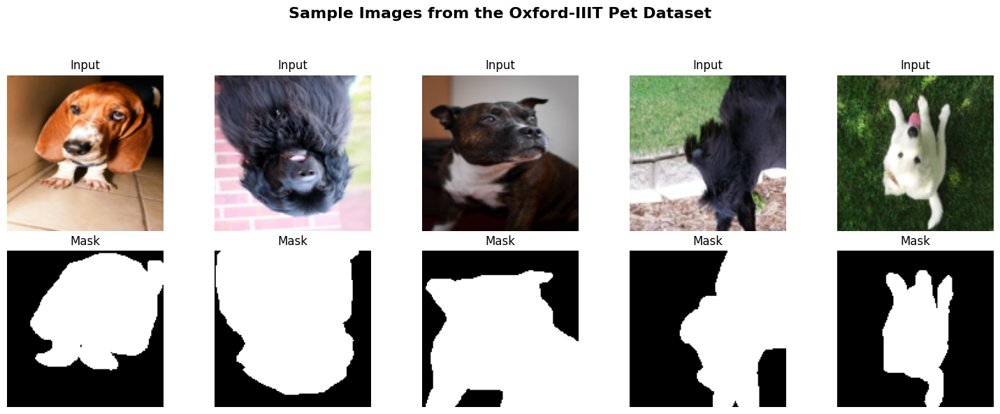

File successfully saved to Drive: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment10_Image_Segmentation/Results/Dataset_Samples/dataset_samples.png


In [ ]:
images, masks = next(iter(train_loader))

plt.figure(figsize=(15, 6))

# Add an overall figure title
plt.suptitle("Sample Images from the Oxford-IIIT Pet Dataset", fontsize=16, fontweight="bold")

for i in range(5):

    plt.subplot(2, 5, i + 1)
    image = images[i].permute(1, 2, 0).numpy()

    image = image * np.array([0.229, 0.224, 0.225])
    image = image + np.array([0.485, 0.456, 0.406])
    image = np.clip(image, 0, 1)

    plt.imshow(image)
    plt.axis("off")
    plt.title("Input", fontsize=12)

    plt.subplot(2, 5, i + 6)
    plt.imshow(masks[i][0], cmap="gray")
    plt.axis("off")
    plt.title("Mask", fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.93])

save_path = os.path.join(SAMPLE_DIR, "dataset_samples.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"File successfully saved to Drive: {save_path}")

#Loss functions

In [ ]:
bce_loss = nn.BCEWithLogitsLoss()

def dice_loss(logits, targets, smooth=1.0):

    probs = torch.sigmoid(logits)

    probs = probs.view(probs.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    intersection = (probs * targets).sum(dim=1)

    dice = (
        2.0 * intersection + smooth
    ) / (
        probs.sum(dim=1) +
        targets.sum(dim=1) +
        smooth
    )

    return 1 - dice.mean()


def segmentation_loss(logits, targets):

    return (
        0.5 * bce_loss(logits, targets)
        +
        0.5 * dice_loss(logits, targets)
    )

#Create the first six models

In [ ]:
def create_smp_model(model_name):

    if model_name == "UNet":

        return smp.Unet(
            encoder_name="resnet18",
            encoder_weights="imagenet",
            in_channels=3,
            classes=1
        )

    elif model_name == "UNet++":

        return smp.UnetPlusPlus(
            encoder_name="resnet18",
            encoder_weights="imagenet",
            in_channels=3,
            classes=1
        )

    elif model_name == "FPN":

        return smp.FPN(
            encoder_name="resnet18",
            encoder_weights="imagenet",
            in_channels=3,
            classes=1
        )

    elif model_name == "Attention U-Net":

        return smp.Unet(
            encoder_name="resnet18",
            encoder_weights="imagenet",
            in_channels=3,
            classes=1,
            decoder_attention_type="scse"
        )

    elif model_name == "DeepLabV3+":

        return smp.DeepLabV3Plus(
            encoder_name="resnet18",
            encoder_weights="imagenet",
            in_channels=3,
            classes=1
        )

    else:
        raise ValueError("Unknown model")

#Simple BASNet implementation

In [ ]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class SimpleBASNet(nn.Module):

    def __init__(self):

        super().__init__()

        self.enc1 = ConvBlock(3, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = ConvBlock(128, 256)

        self.dec3 = ConvBlock(256 + 128, 128)
        self.dec2 = ConvBlock(128 + 64, 64)
        self.dec1 = ConvBlock(64 + 32, 32)

        self.initial_prediction = nn.Conv2d(
            32, 1, 1
        )

        # Residual refinement
        self.refine = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(16, 16, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(16, 1, 3, padding=1)
        )

    def forward(self, x):

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        b = self.bottleneck(
            self.pool(e3)
        )

        d3 = F.interpolate(
            b,
            size=e3.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        d3 = self.dec3(
            torch.cat([d3, e3], dim=1)
        )

        d2 = F.interpolate(
            d3,
            size=e2.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        d2 = self.dec2(
            torch.cat([d2, e2], dim=1)
        )

        d1 = F.interpolate(
            d2,
            size=e1.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        d1 = self.dec1(
            torch.cat([d1, e1], dim=1)
        )

        initial = self.initial_prediction(d1)

        refined = initial + self.refine(
            torch.sigmoid(initial)
        )

        refined = F.interpolate(
            refined,
            size=x.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        return refined

#SegFormer

In [ ]:
class SegFormerWrapper(nn.Module):

    def __init__(self):

        super().__init__()

        self.model = SegformerForSemanticSegmentation.from_pretrained(
            "nvidia/mit-b0",
            num_labels=1,
            ignore_mismatched_sizes=True
        )

    def forward(self, x):

        outputs = self.model(
            pixel_values=x
        )

        logits = outputs.logits

        logits = F.interpolate(
            logits,
            size=x.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        return logits

#Model list

In [ ]:
MODEL_NAMES = [
    "UNet",
    "UNet++",
    "FPN",
    "Attention U-Net",
    "BASNet",
    "DeepLabV3+",
    "SegFormer"
]

print("Models:")
for name in MODEL_NAMES:
    print("-", name)

Models:
- UNet
- UNet++
- FPN
- Attention U-Net
- BASNet
- DeepLabV3+
- SegFormer


#Model factory

In [ ]:
def create_model(name):

    if name == "BASNet":
        model = SimpleBASNet()

    elif name == "SegFormer":
        model = SegFormerWrapper()

    else:
        model = create_smp_model(name)

    return model.to(DEVICE)

#Check models before training

In [ ]:
for name in MODEL_NAMES:

    print("\nTesting:", name)

    model = create_model(name)
    model.eval()

    dummy = torch.randn(
        1, 3, IMAGE_SIZE, IMAGE_SIZE
    ).to(DEVICE)

    with torch.no_grad():
        output = model(dummy)

    print("Input :", dummy.shape)
    print("Output:", output.shape)

    del model
    del dummy
    del output

    torch.cuda.empty_cache()


Testing: UNet


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Input : torch.Size([1, 3, 128, 128])
Output: torch.Size([1, 1, 128, 128])

Testing: UNet++
Input : torch.Size([1, 3, 128, 128])
Output: torch.Size([1, 1, 128, 128])

Testing: FPN
Input : torch.Size([1, 3, 128, 128])
Output: torch.Size([1, 1, 128, 128])

Testing: Attention U-Net
Input : torch.Size([1, 3, 128, 128])
Output: torch.Size([1, 1, 128, 128])

Testing: BASNet
Input : torch.Size([1, 3, 128, 128])
Output: torch.Size([1, 1, 128, 128])

Testing: DeepLabV3+
Input : torch.Size([1, 3, 128, 128])
Output: torch.Size([1, 1, 128, 128])

Testing: SegFormer


...

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 14.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.batch_norm.running_mean                     

Input : torch.Size([1, 3, 128, 128])
Output: torch.Size([1, 1, 128, 128])


#Parameter counting

In [ ]:
def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


parameter_results = []

for name in MODEL_NAMES:

    model = create_model(name)

    params = count_parameters(model)

    parameter_results.append({
        "Model": name,
        "Trainable Parameters": params
    })

    print(name, ":", params)

    del model
    torch.cuda.empty_cache()

parameter_df = pd.DataFrame(parameter_results)

parameter_df.to_csv(
    os.path.join(
        COMPARISON_DIR,
        "model_parameters.csv"
    ),
    index=False
)

parameter_df

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

UNet : 14328209
UNet++ : 15970449
FPN : 13047233
Attention U-Net : 14442200
BASNet : 1952322
DeepLabV3+ : 12329297


[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.batch_norm.running_mean                     

SegFormer : 3714401


,Model,Trainable Parameters
0,UNet,14328209
1,UNet++,15970449
2,FPN,13047233
3,Attention U-Net,14442200
4,BASNet,1952322
5,DeepLabV3+,12329297
6,SegFormer,3714401


#Training function

In [ ]:
def train_model(
    model,
    model_name,
    epochs=EPOCHS
):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")

    model_folder = os.path.join(
        MODEL_DIR,
        model_name.replace(" ", "_")
    )

    os.makedirs(
        model_folder,
        exist_ok=True
    )

    start_time = time.time()

    for epoch in range(epochs):

        # -------------------------
        # Training
        # -------------------------

        model.train()

        train_loss = 0.0

        for images, masks in train_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            masks = masks.to(
                DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad()

            outputs = model(images)

            loss = segmentation_loss(
                outputs,
                masks
            )

            loss.backward()

            optimizer.step()

            train_loss += loss.item()

        train_loss /= len(train_loader)

        # -------------------------
        # Validation
        # -------------------------

        model.eval()

        val_loss = 0.0

        with torch.no_grad():

            for images, masks in val_loader:

                images = images.to(DEVICE)
                masks = masks.to(DEVICE)

                outputs = model(images)

                loss = segmentation_loss(
                    outputs,
                    masks
                )

                val_loss += loss.item()

        val_loss /= len(val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(
            f"{model_name} | "
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            torch.save(
                model.state_dict(),
                os.path.join(
                    model_folder,
                    "best_model.pth"
                )
            )

    training_time = time.time() - start_time

    torch.save(
        model.state_dict(),
        os.path.join(
            model_folder,
            "last_model.pth"
        )
    )

    with open(
        os.path.join(
            model_folder,
            "history.json"
        ),
        "w"
    ) as f:

        json.dump(
            history,
            f,
            indent=4
        )

    return history, training_time

#Training all seven models

In [ ]:
all_histories = {}
training_times = {}

for name in MODEL_NAMES:

    print("\n" + "=" * 60)
    print("TRAINING:", name)
    print("=" * 60)

    model = create_model(name)

    history, train_time = train_model(
        model,
        name
    )

    all_histories[name] = history
    training_times[name] = train_time

    print(
        f"\nFinished {name}"
    )

    print(
        f"Training time: "
        f"{train_time / 60:.2f} minutes"
    )

    del model
    torch.cuda.empty_cache()


TRAINING: UNet
UNet | Epoch 1/10 | Train Loss: 0.3186 | Val Loss: 0.1893
UNet | Epoch 2/10 | Train Loss: 0.1732 | Val Loss: 0.1454
UNet | Epoch 3/10 | Train Loss: 0.1445 | Val Loss: 0.1325
UNet | Epoch 4/10 | Train Loss: 0.1285 | Val Loss: 0.1359
UNet | Epoch 5/10 | Train Loss: 0.1185 | Val Loss: 0.1218
UNet | Epoch 6/10 | Train Loss: 0.1107 | Val Loss: 0.1136
UNet | Epoch 7/10 | Train Loss: 0.1076 | Val Loss: 0.1129
UNet | Epoch 8/10 | Train Loss: 0.1004 | Val Loss: 0.1092
UNet | Epoch 9/10 | Train Loss: 0.0954 | Val Loss: 0.1124
UNet | Epoch 10/10 | Train Loss: 0.0913 | Val Loss: 0.1102

Finished UNet
Training time: 25.06 minutes

TRAINING: UNet++
UNet++ | Epoch 1/10 | Train Loss: 0.2929 | Val Loss: 0.1857
UNet++ | Epoch 2/10 | Train Loss: 0.1677 | Val Loss: 0.1412
UNet++ | Epoch 3/10 | Train Loss: 0.1375 | Val Loss: 0.1259
UNet++ | Epoch 4/10 | Train Loss: 0.1189 | Val Loss: 0.1205
UNet++ | Epoch 5/10 | Train Loss: 0.1136 | Val Loss: 0.1185
UNet++ | Epoch 6/10 | Train Loss: 0.1026 

[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.



Finished DeepLabV3+
Training time: 5.27 minutes

TRAINING: SegFormer


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.batch_norm.running_mean                     

SegFormer | Epoch 1/10 | Train Loss: 0.2488 | Val Loss: 0.1680
SegFormer | Epoch 2/10 | Train Loss: 0.1613 | Val Loss: 0.1386
SegFormer | Epoch 3/10 | Train Loss: 0.1381 | Val Loss: 0.1349
SegFormer | Epoch 4/10 | Train Loss: 0.1247 | Val Loss: 0.1176
SegFormer | Epoch 5/10 | Train Loss: 0.1193 | Val Loss: 0.1189
SegFormer | Epoch 6/10 | Train Loss: 0.1115 | Val Loss: 0.1138
SegFormer | Epoch 7/10 | Train Loss: 0.1074 | Val Loss: 0.1131
SegFormer | Epoch 8/10 | Train Loss: 0.1057 | Val Loss: 0.1136
SegFormer | Epoch 9/10 | Train Loss: 0.0995 | Val Loss: 0.1111
SegFormer | Epoch 10/10 | Train Loss: 0.1006 | Val Loss: 0.1139

Finished SegFormer
Training time: 5.82 minutes


#Plot learning curves

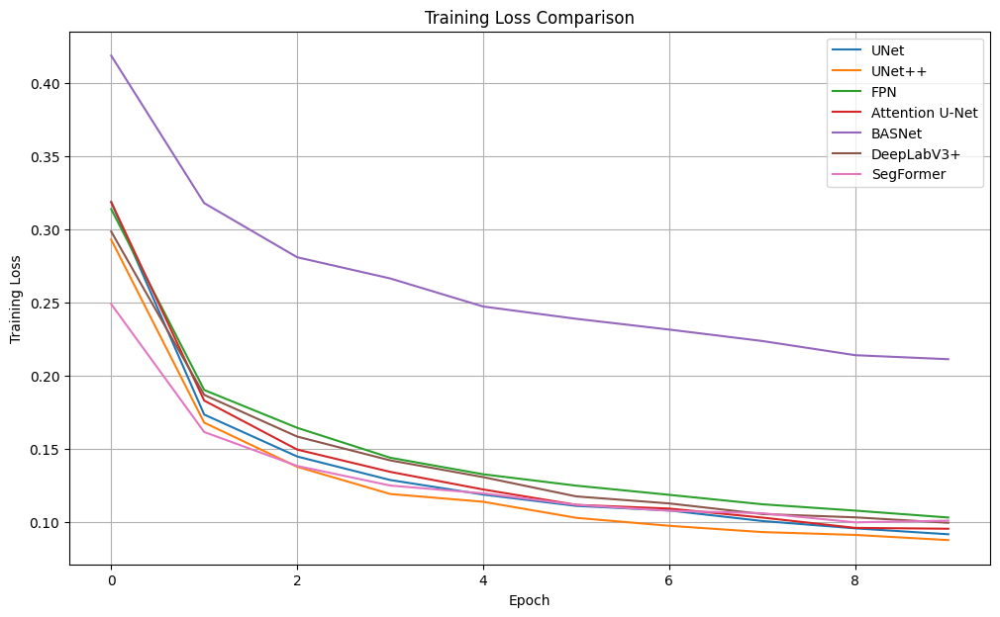

In [ ]:
plt.figure(figsize=(12, 7))

for name in MODEL_NAMES:

    history = all_histories[name]

    plt.plot(
        history["train_loss"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        LEARNING_CURVE_DIR,
        "training_loss_comparison.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

#Validation loss curves

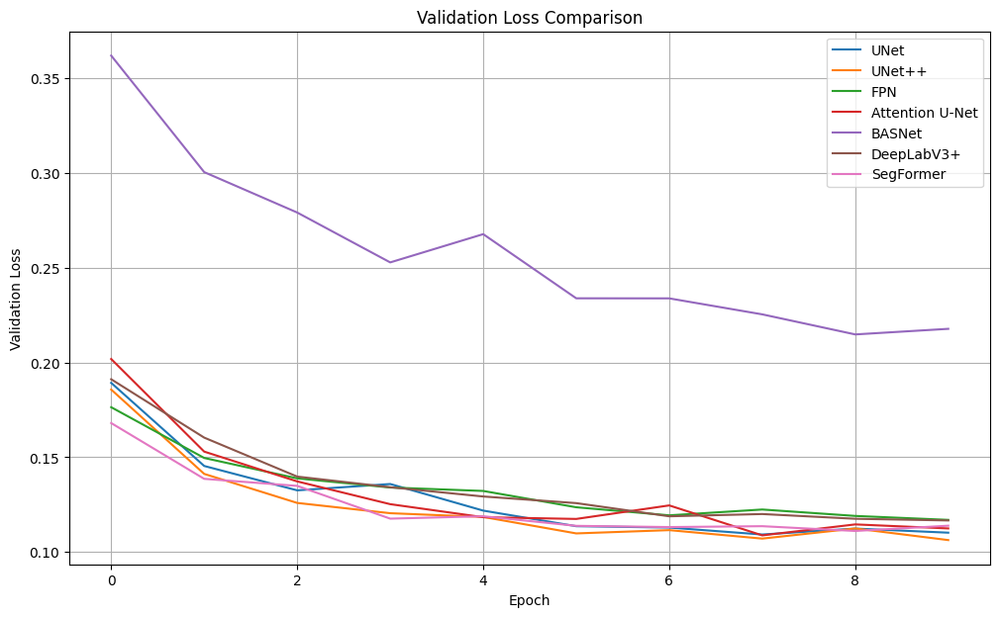

In [ ]:
plt.figure(figsize=(12, 7))

for name in MODEL_NAMES:

    history = all_histories[name]

    plt.plot(
        history["val_loss"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        LEARNING_CURVE_DIR,
        "validation_loss_comparison.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

#Evaluation functions

In [ ]:
def calculate_metrics(pred, target):

    pred = pred.astype(np.uint8)
    target = target.astype(np.uint8)

    pred_flat = pred.flatten()
    target_flat = target.flatten()

    accuracy = accuracy_score(
        target_flat,
        pred_flat
    )

    precision = precision_score(
        target_flat,
        pred_flat,
        zero_division=0
    )

    recall = recall_score(
        target_flat,
        pred_flat,
        zero_division=0
    )

    f1 = f1_score(
        target_flat,
        pred_flat,
        zero_division=0
    )

    intersection = np.logical_and(
        pred == 1,
        target == 1
    ).sum()

    union = np.logical_or(
        pred == 1,
        target == 1
    ).sum()

    iou = (
        intersection / union
        if union > 0
        else 1.0
    )

    dice = (
        2 * intersection /
        (
            pred.sum() +
            target.sum()
        )
        if (
            pred.sum() +
            target.sum()
        ) > 0
        else 1.0
    )

    # Binary mean IoU:
    iou_background = (
        np.logical_and(
            pred == 0,
            target == 0
        ).sum()
        /
        np.logical_or(
            pred == 0,
            target == 0
        ).sum()
    )

    miou = (
        iou_background + iou
    ) / 2

    return {
        "IoU": iou,
        "Dice": dice,
        "Pixel Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Mean IoU": miou
    }

#Evaluate one model

In [ ]:
def evaluate_model(model, model_name):

    model.eval()

    all_predictions = []
    all_targets = []

    total_inference_time = 0.0
    total_images = 0

    with torch.no_grad():

        for images, masks in test_loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            start = time.time()

            outputs = model(images)

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            total_inference_time += (
                time.time() - start
            )

            probabilities = torch.sigmoid(
                outputs
            )

            predictions = (
                probabilities >= 0.5
            ).float()

            all_predictions.append(
                predictions.cpu().numpy()
            )

            all_targets.append(
                masks.cpu().numpy()
            )

            total_images += images.size(0)

    predictions = np.concatenate(
        all_predictions
    ).astype(np.uint8)

    targets = np.concatenate(
        all_targets
    ).astype(np.uint8)

    predictions = predictions[:, 0]
    targets = targets[:, 0]

    metrics = calculate_metrics(
        predictions,
        targets
    )

    metrics["Inference Time (sec)"] = (
        total_inference_time
    )

    metrics["Inference Time/Image (ms)"] = (
        total_inference_time /
        total_images *
        1000
    )

    return metrics, predictions, targets

#Evaluate all models

In [ ]:
final_results = {}

all_predictions = {}
all_targets = {}

for name in MODEL_NAMES:

    print("\nEvaluating:", name)

    model = create_model(name)

    model_folder = os.path.join(
        MODEL_DIR,
        name.replace(" ", "_")
    )

    best_model_path = os.path.join(
        model_folder,
        "best_model.pth"
    )

    model.load_state_dict(
        torch.load(
            best_model_path,
            map_location=DEVICE
        )
    )

    metrics, predictions, targets = evaluate_model(
        model,
        name
    )

    final_results[name] = metrics

    all_predictions[name] = predictions
    all_targets[name] = targets

    print(metrics)

    del model
    torch.cuda.empty_cache()


Evaluating: UNet
{'IoU': np.float64(0.8861840295708208), 'Dice': np.float64(0.9396580775550959), 'Pixel Accuracy': 0.9497285407776728, 'Precision': 0.9538933206273752, 'Recall': 0.9258414610019071, 'F1-score': 0.9396580775550959, 'Mean IoU': np.float64(0.9017898038190061), 'Inference Time (sec)': 4.203362226486206, 'Inference Time/Image (ms)': 1.1456424711055344}

Evaluating: UNet++
{'IoU': np.float64(0.8910862241954924), 'Dice': np.float64(0.9424067636837439), 'Pixel Accuracy': 0.9519117661541378, 'Precision': 0.9545009301581299, 'Recall': 0.930615244849967, 'F1-score': 0.9424067636837439, 'Mean IoU': np.float64(0.9059031465871352), 'Inference Time (sec)': 9.846365213394165, 'Inference Time/Image (ms)': 2.6836645443974283}

Evaluating: FPN
{'IoU': np.float64(0.8831933562866573), 'Dice': np.float64(0.9379741632353324), 'Pixel Accuracy': 0.9475458643682714, 'Precision': 0.9378197182451496, 'Recall': 0.9381286591034899, 'F1-score': 0.9379741632353324, 'Mean IoU': np.float64(0.8981301980

[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


{'IoU': np.float64(0.8827228696986006), 'Dice': np.float64(0.9377087662826479), 'Pixel Accuracy': 0.9475946725308326, 'Precision': 0.9424669169976656, 'Recall': 0.9329984183528363, 'F1-score': 0.9377087662826479, 'Mean IoU': np.float64(0.8980909392128784), 'Inference Time (sec)': 5.444591760635376, 'Inference Time/Image (ms)': 1.4839443337790612}

Evaluating: SegFormer


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.batch_norm.running_mean                     

{'IoU': np.float64(0.8913522073335837), 'Dice': np.float64(0.9425554942939013), 'Pixel Accuracy': 0.9510283284305584, 'Precision': 0.9349212520225996, 'Recall': 0.9503154401595466, 'F1-score': 0.9425554942939013, 'Mean IoU': np.float64(0.904745894505723), 'Inference Time (sec)': 8.641717910766602, 'Inference Time/Image (ms)': 2.355333309012429}


#Comparative results table

In [ ]:
results_df = pd.DataFrame(
    final_results
).T.reset_index()

results_df = results_df.rename(
    columns={"index": "Model"}
)

results_df["Training Time (min)"] = [
    training_times[name] / 60
    for name in MODEL_NAMES
]

results_df.to_csv(
    os.path.join(
        COMPARISON_DIR,
        "final_segmentation_results.csv"
    ),
    index=False
)

results_df

,Model,IoU,Dice,Pixel Accuracy,Precision,Recall,F1-score,Mean IoU,Inference Time (sec),Inference Time/Image (ms),Training Time (min)
0,UNet,0.886184,0.939658,0.949729,0.953893,0.925841,0.939658,0.901790,4.203362,1.145642,25.058135
1,UNet++,0.891086,0.942407,0.951912,0.954501,0.930615,0.942407,0.905903,9.846365,2.683665,6.105361
2,FPN,0.883193,0.937974,0.947546,0.937820,0.938129,0.937974,0.898130,5.572166,1.518715,5.103013
3,Attention U-Net,0.888310,0.940852,0.950436,0.949442,0.932415,0.940852,0.903247,6.890768,1.878105,5.503744
4,BASNet,0.785768,0.880033,0.899293,0.886458,0.873702,0.880033,0.813037,8.015625,2.184689,5.356187
5,DeepLabV3+,0.882723,0.937709,0.947595,0.942467,0.932998,0.937709,0.898091,5.444592,1.483944,5.267843
6,SegFormer,0.891352,0.942555,0.951028,0.934921,0.950315,0.942555,0.904746,8.641718,2.355333,5.822925


#Confusion matrices

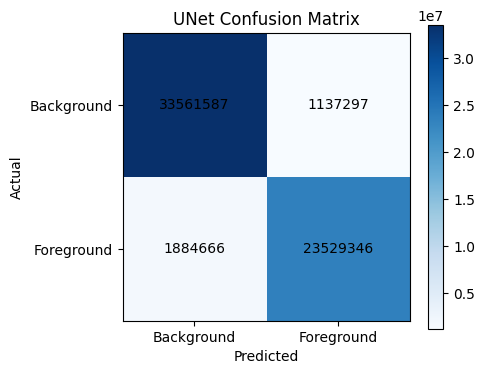

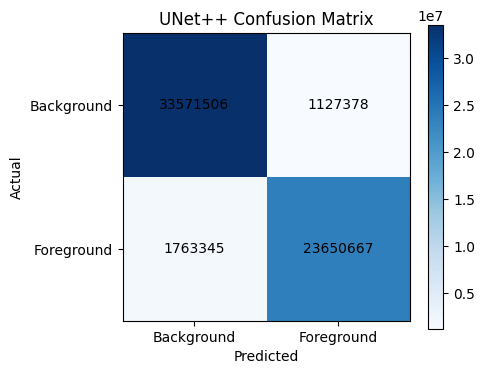

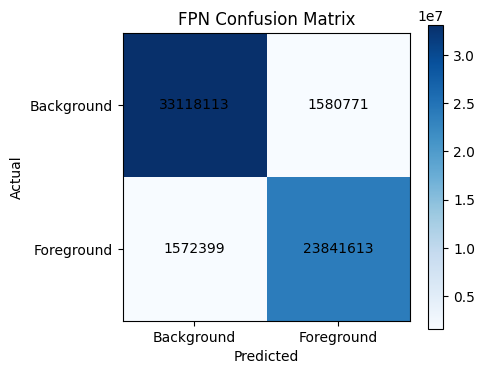

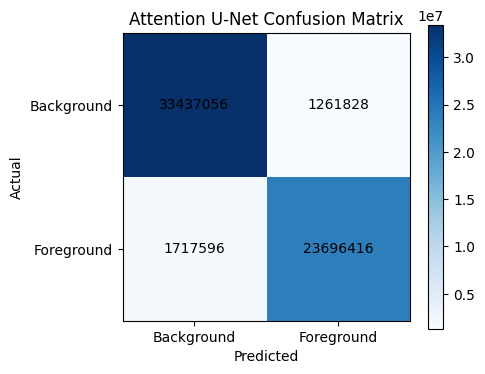

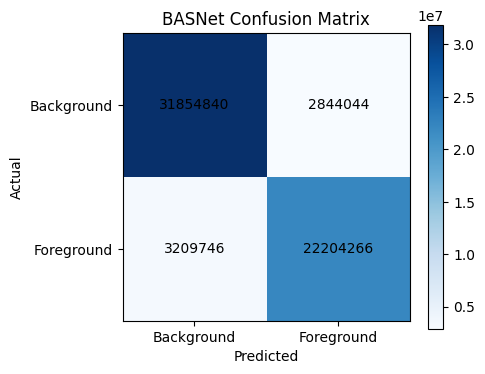

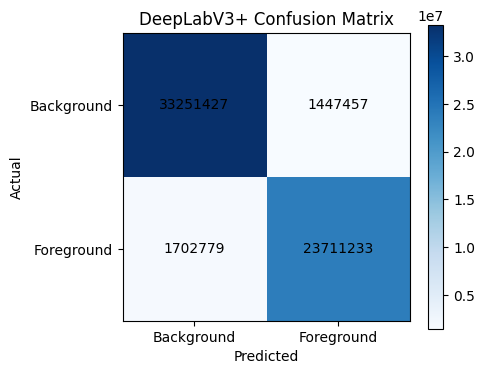

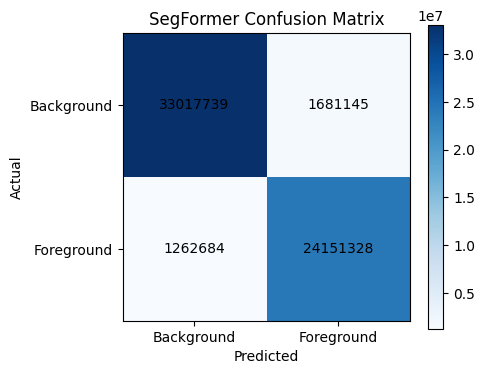

In [ ]:
for name in MODEL_NAMES:

    pred = all_predictions[name].flatten()
    target = all_targets[name].flatten()

    cm = confusion_matrix(
        target,
        pred
    )

    cm_df = pd.DataFrame(
        cm,
        index=["Background", "Foreground"],
        columns=["Background", "Foreground"]
    )

    cm_df.to_csv(
        os.path.join(
            CONFUSION_DIR,
            f"{name.replace(' ', '_')}_confusion_matrix.csv"
        )
    )

    plt.figure(figsize=(5, 4))

    plt.imshow(
        cm,
        cmap="Blues"
    )

    plt.title(
        f"{name} Confusion Matrix"
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.xticks(
        [0, 1],
        ["Background", "Foreground"]
    )

    plt.yticks(
        [0, 1],
        ["Background", "Foreground"]
    )

    for i in range(2):
        for j in range(2):

            plt.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

    plt.colorbar()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            CONFUSION_DIR,
            f"{name.replace(' ', '_')}_confusion_matrix.png"
        ),
        dpi=150
    )

    plt.show()

#Metric comparison graph

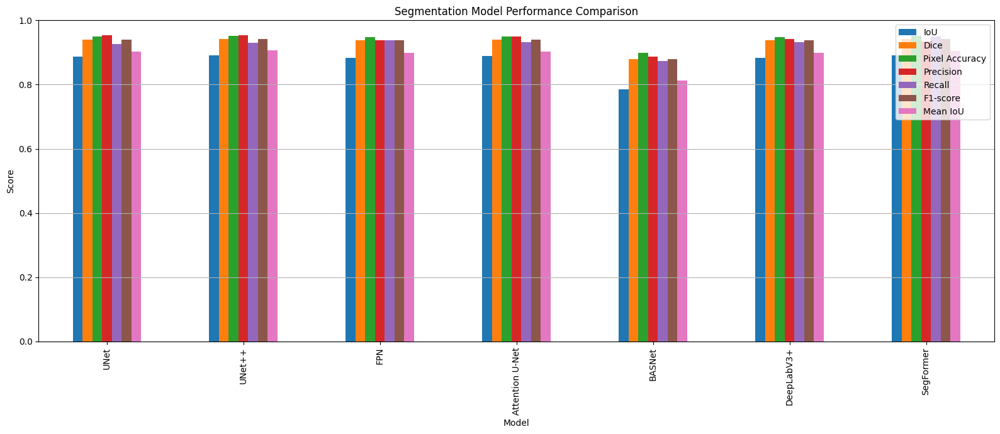

In [ ]:
metrics_to_plot = [
    "IoU",
    "Dice",
    "Pixel Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "Mean IoU"
]

results_df.set_index(
    "Model"
)[metrics_to_plot].plot(
    kind="bar",
    figsize=(16, 7)
)

plt.ylabel("Score")
plt.title("Segmentation Model Performance Comparison")
plt.ylim(0, 1)
plt.grid(axis="y")

plt.tight_layout()

plt.savefig(
    os.path.join(
        COMPARISON_DIR,
        "model_performance_comparison.png"
    ),
    dpi=150
)

plt.show()

#Display prediction examples

In [ ]:
def show_predictions(model_name, number=4):

    predictions = all_predictions[model_name]
    targets = all_targets[model_name]

    images, _ = next(iter(test_loader))

    plt.figure(figsize=(12, 8))

    for i in range(number):

        image = images[i].permute(
            1, 2, 0
        ).numpy()

        image = image * np.array(
            [0.229, 0.224, 0.225]
        )

        image = image + np.array(
            [0.485, 0.456, 0.406]
        )

        image = np.clip(
            image,
            0,
            1
        )

        plt.subplot(
            3,
            number,
            i + 1
        )

        plt.imshow(image)
        plt.axis("off")
        plt.title("Input")

        plt.subplot(
            3,
            number,
            number + i + 1
        )

        plt.imshow(
            targets[i],
            cmap="gray"
        )

        plt.axis("off")
        plt.title("Ground Truth")

        plt.subplot(
            3,
            number,
            2 * number + i + 1
        )

        plt.imshow(
            predictions[i],
            cmap="gray"
        )

        plt.axis("off")
        plt.title("Prediction")

    plt.suptitle(
        model_name,
        fontsize=14
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            PREDICTION_DIR,
            f"{model_name.replace(' ', '_')}_predictions.png"
        ),
        dpi=150
    )

    plt.show()

#For all models

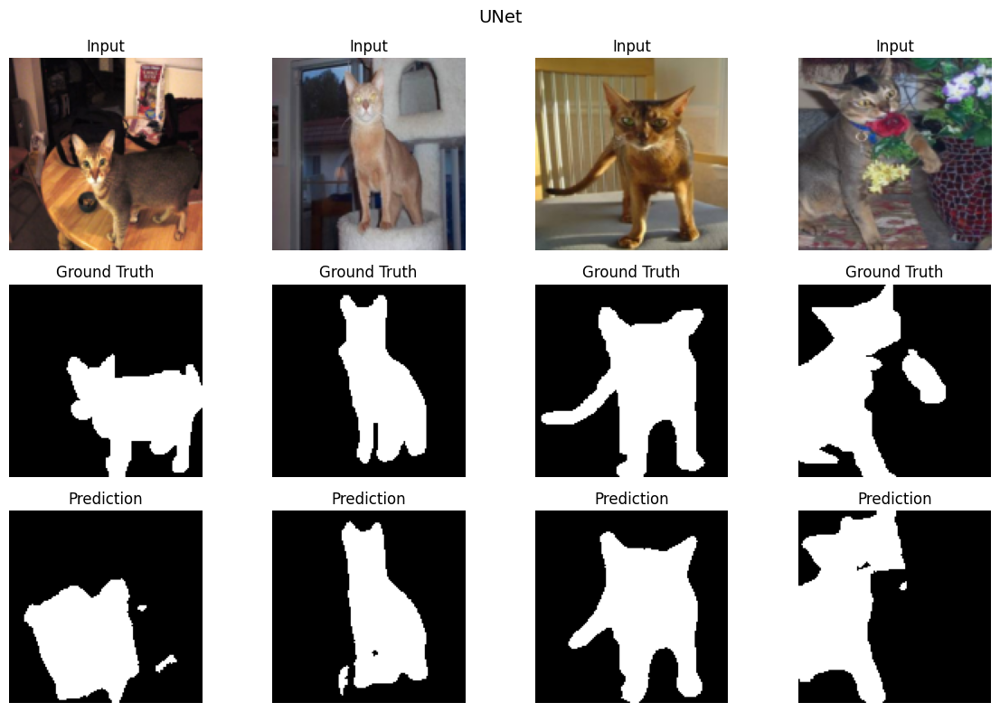

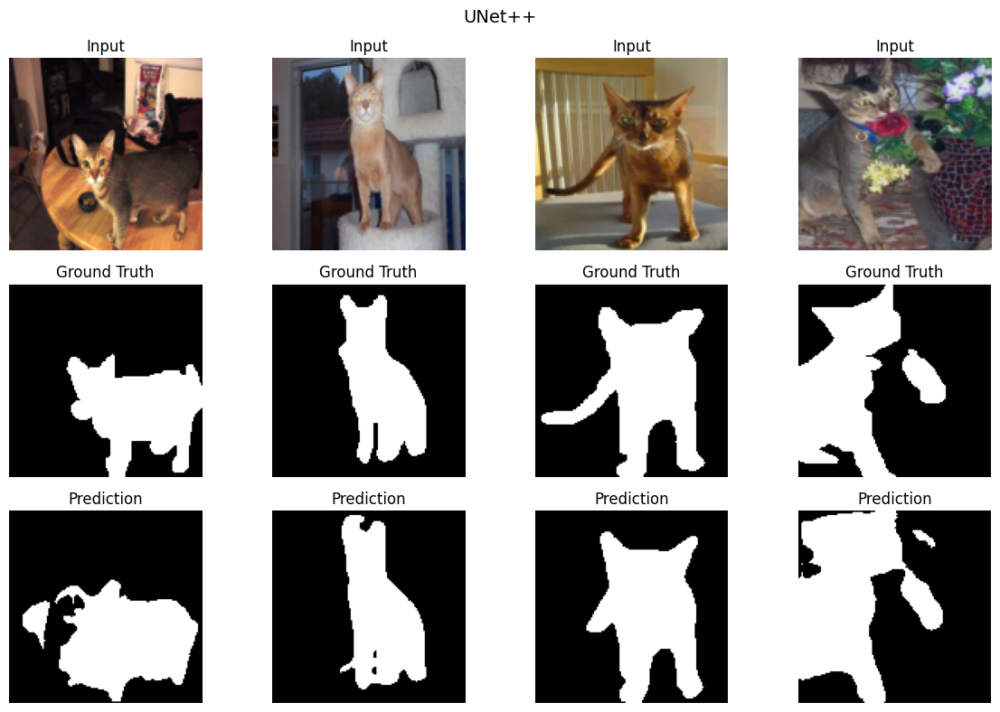

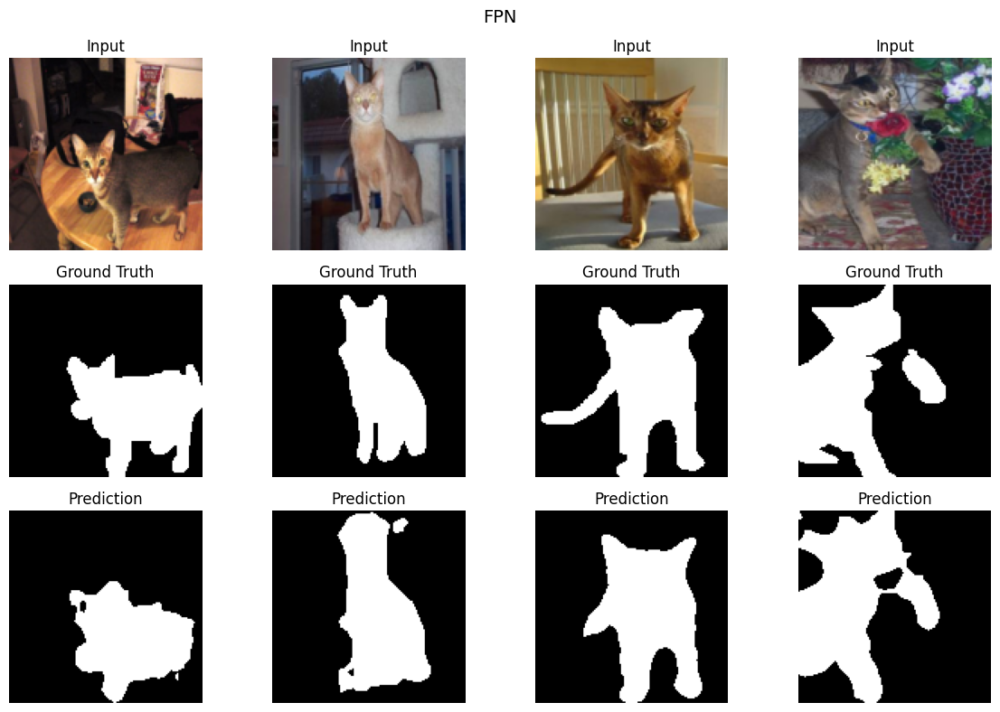

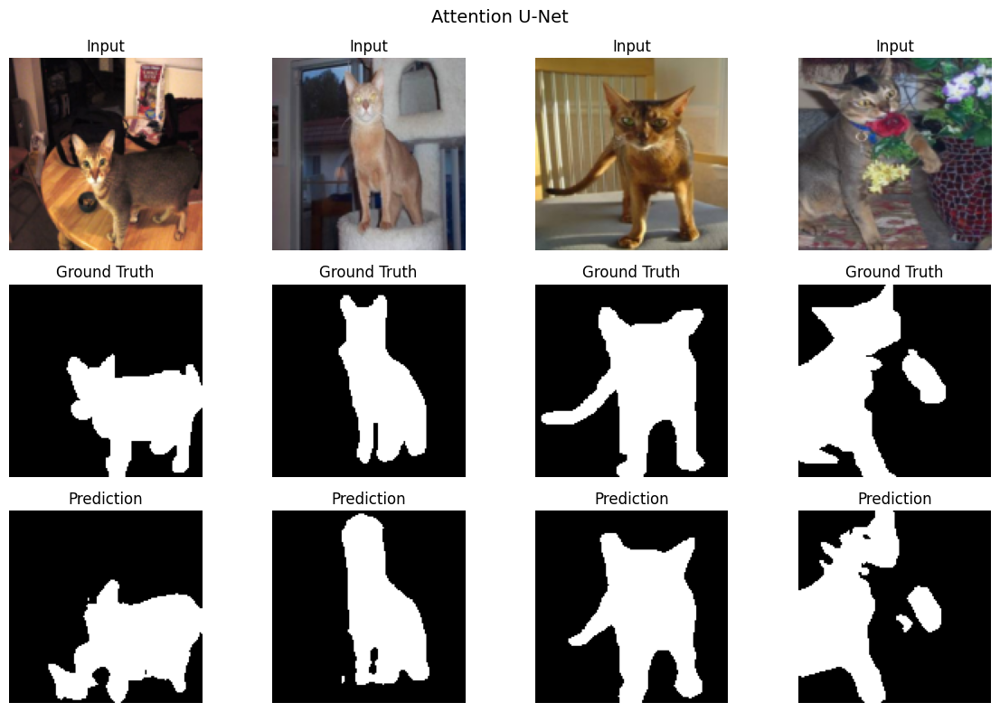

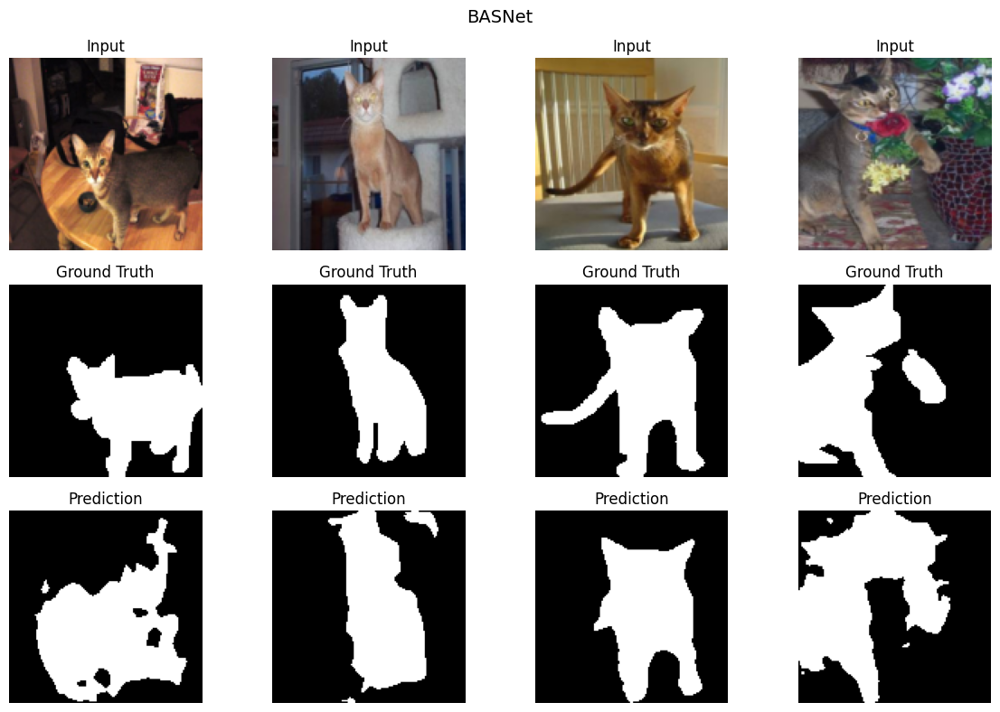

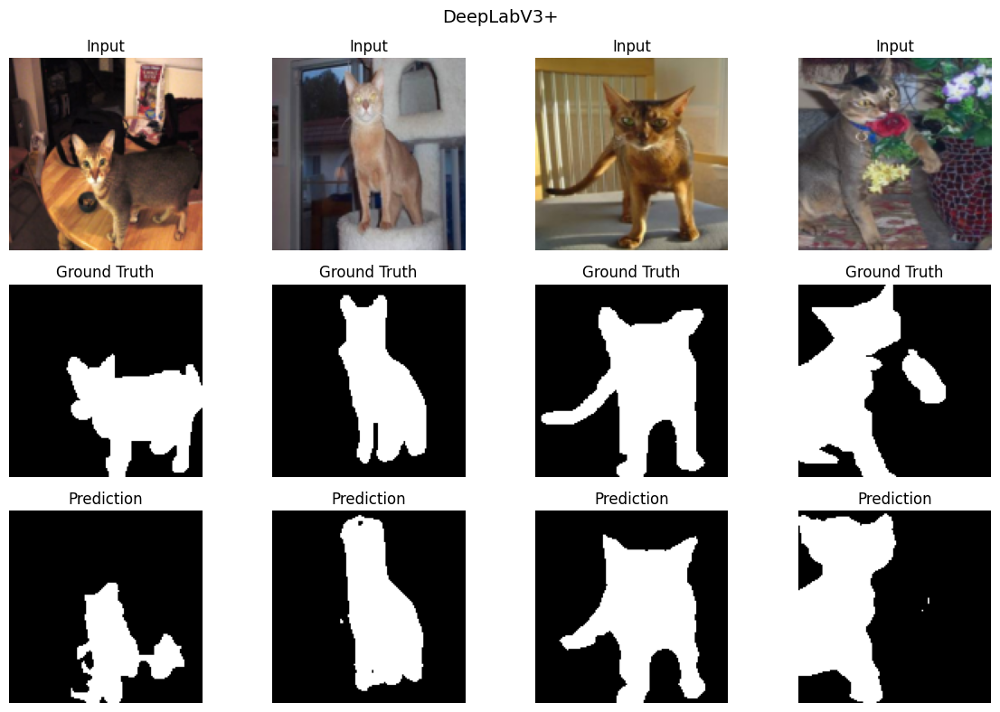

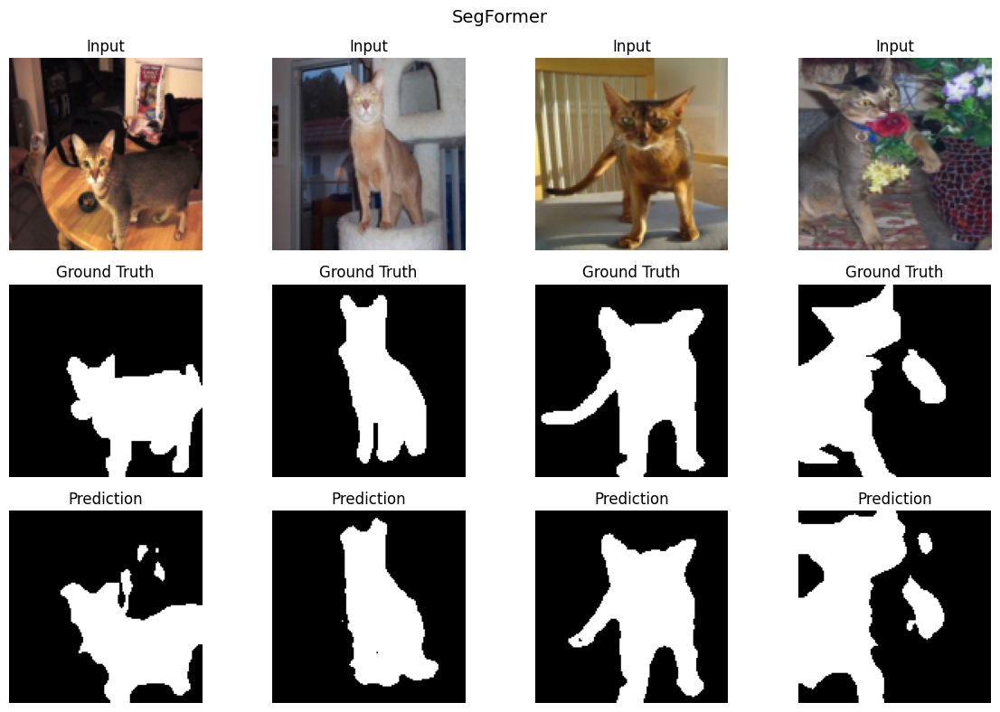

In [ ]:
for name in MODEL_NAMES:
    show_predictions(name)

#Task 3 - Custom model
### Attention Boundary Refinement U-Net (ABR-U-Net)
Input<br>
  ↓ <br>
ResNet18 Encoder<br>
  ↓<br>
Multi-scale Features<br>
  ↓<br>
Attention Skip Connections<br>
  ↓<br>
U-Net Decoder<br>
  ↓<br>
Initial Segmentation<br>
  ↓<br>
Boundary Refinement Module<br>
  ↓<br>
Final Mask<br>
#### The meaningful modifications are:



1.   Attention skip connections
2.   Boundary refinement module
2.   Combined segmentation + boundary loss

#Custom Attention Gate

In [ ]:
class AttentionGate(nn.Module):

    def __init__(
        self,
        channels
    ):

        super().__init__()

        self.attention = nn.Sequential(

            nn.Conv2d(
                channels,
                channels // 2,
                1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                channels // 2,
                1,
                1
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        attention = self.attention(x)

        return x * attention

#Custom Boundary Refinement U-Net

In [ ]:
class ABRUNet(nn.Module):

    def __init__(self):

        super().__init__()

        self.encoder = smp.Unet(
            encoder_name="resnet18",
            encoder_weights="imagenet",
            in_channels=3,
            classes=1,
            decoder_attention_type="scse"
        )

        self.boundary_refinement = nn.Sequential(

            nn.Conv2d(
                1,
                16,
                3,
                padding=1
            ),

            nn.BatchNorm2d(16),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                16,
                16,
                3,
                padding=1
            ),

            nn.BatchNorm2d(16),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                16,
                1,
                3,
                padding=1
            )
        )

    def forward(self, x):

        initial = self.encoder(x)

        refined = self.boundary_refinement(
            torch.sigmoid(initial)
        )

        return initial + refined

#Boundary loss

In [ ]:
def boundary_map(mask):

    max_pool = F.max_pool2d(
        mask,
        kernel_size=3,
        stride=1,
        padding=1
    )

    min_pool = -F.max_pool2d(
        -mask,
        kernel_size=3,
        stride=1,
        padding=1
    )

    boundary = max_pool - min_pool

    return boundary


def custom_loss(logits, target):

    base_loss = segmentation_loss(
        logits,
        target
    )

    pred_prob = torch.sigmoid(logits)

    pred_boundary = boundary_map(
        pred_prob
    )

    target_boundary = boundary_map(
        target
    )

    boundary_loss = F.l1_loss(
        pred_boundary,
        target_boundary
    )

    return (
        base_loss +
        0.2 * boundary_loss
    )

#Train custom model

In [ ]:
custom_model = ABRUNet().to(DEVICE)

optimizer = torch.optim.Adam(
    custom_model.parameters(),
    lr=LEARNING_RATE
)

custom_history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")

custom_start = time.time()

for epoch in range(EPOCHS):

    custom_model.train()

    train_loss = 0

    for images, masks in train_loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        optimizer.zero_grad()

        outputs = custom_model(images)

        loss = custom_loss(
            outputs,
            masks
        )

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    custom_model.eval()

    val_loss = 0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            outputs = custom_model(images)

            loss = custom_loss(
                outputs,
                masks
            )

            val_loss += loss.item()

    val_loss /= len(val_loader)

    custom_history["train_loss"].append(
        train_loss
    )

    custom_history["val_loss"].append(
        val_loss
    )

    print(
        f"ABR-U-Net | "
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train: {train_loss:.4f} | "
        f"Val: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            custom_model.state_dict(),
            os.path.join(
                MODEL_DIR,
                "ABR_UNet_best.pth"
            )
        )

custom_training_time = (
    time.time() - custom_start
)

ABR-U-Net | Epoch 1/10 | Train: 0.3255 | Val: 0.1844
ABR-U-Net | Epoch 2/10 | Train: 0.1793 | Val: 0.1542
ABR-U-Net | Epoch 3/10 | Train: 0.1535 | Val: 0.1368
ABR-U-Net | Epoch 4/10 | Train: 0.1389 | Val: 0.1350
ABR-U-Net | Epoch 5/10 | Train: 0.1304 | Val: 0.1276
ABR-U-Net | Epoch 6/10 | Train: 0.1231 | Val: 0.1303
ABR-U-Net | Epoch 7/10 | Train: 0.1155 | Val: 0.1241
ABR-U-Net | Epoch 8/10 | Train: 0.1139 | Val: 0.1388
ABR-U-Net | Epoch 9/10 | Train: 0.1110 | Val: 0.1242
ABR-U-Net | Epoch 10/10 | Train: 0.1044 | Val: 0.1200


#Evaluate custom model

In [ ]:
custom_model.load_state_dict(
    torch.load(
        os.path.join(
            MODEL_DIR,
            "ABR_UNet_best.pth"
        ),
        map_location=DEVICE
    )
)

custom_metrics, custom_predictions, custom_targets = evaluate_model(
    custom_model,
    "ABR-U-Net"
)

custom_metrics

{'IoU': np.float64(0.8909837294359004),
 'Dice': np.float64(0.9423494402055906),
 'Pixel Accuracy': 0.951429407094278,
 'Precision': 0.9457652240990375,
 'Recall': 0.9389582408318686,
 'F1-score': 0.9423494402055906,
 'Mean IoU': np.float64(0.9052201007000965),
 'Inference Time (sec)': 7.4961748123168945,
 'Inference Time/Image (ms)': 2.0431111508086386}

#Visualize samples

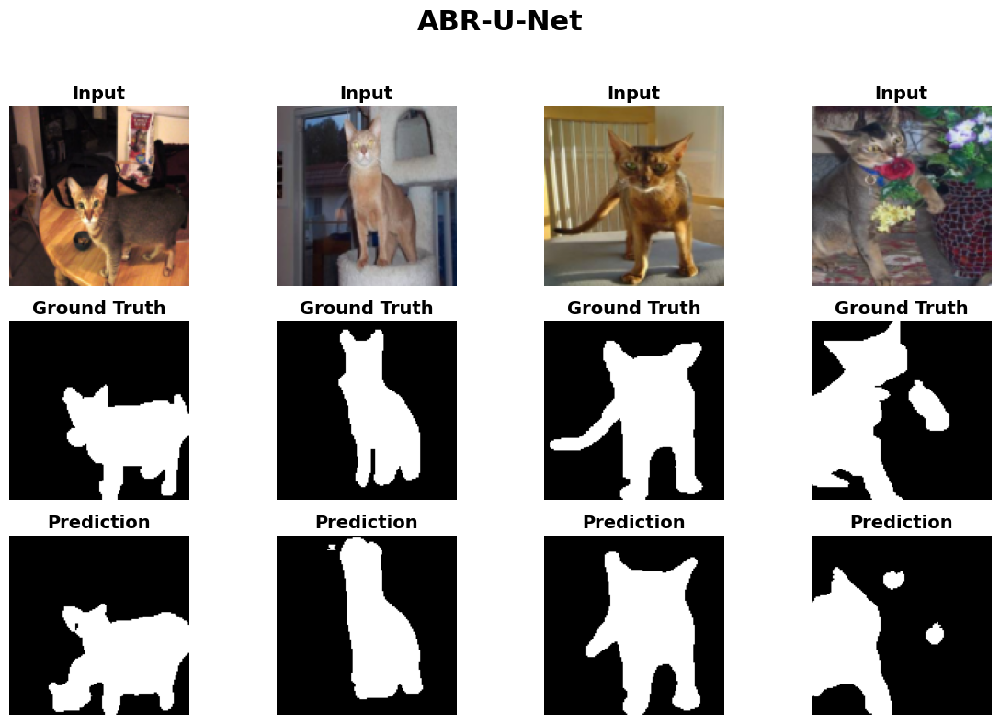

Saved to:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment10_Image_Segmentation/Results/Predictions/ABR_UNet_4_Sample_Predictions.png


In [ ]:

custom_model.eval()

# Select 4 samples from the Oxford-IIIT Pet test set
sample_indices = [0, 1, 2, 3]

fig, axes = plt.subplots(
    3, 4,
    figsize=(12, 8)
)

fig.suptitle(
    "ABR-U-Net",
    fontsize=22,
    fontweight="bold",
    y=0.98
)

with torch.no_grad():

    for col, idx in enumerate(sample_indices):

        # Get image and ground truth from test dataset
        image, mask = test_dataset[idx]

        # Model prediction
        input_tensor = image.unsqueeze(0).to(DEVICE)

        output = custom_model(input_tensor)

        probability = torch.sigmoid(output)

        prediction = (
            probability > 0.5
        ).float()

        # ----------------------------------------------------
        # Input image
        # ----------------------------------------------------

        image_np = (
            image.cpu()
            .numpy()
            .transpose(1, 2, 0)
        )

        # Undo ImageNet normalization
        mean = np.array(
            [0.485, 0.456, 0.406]
        )

        std = np.array(
            [0.229, 0.224, 0.225]
        )

        image_np = (
            image_np * std + mean
        )

        image_np = np.clip(
            image_np,
            0,
            1
        )

        # ----------------------------------------------------
        # Ground truth
        # ----------------------------------------------------

        mask_np = (
            mask.cpu()
            .numpy()
            .squeeze()
        )

        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------

        pred_np = (
            prediction.cpu()
            .numpy()
            .squeeze()
        )

        # ----------------------------------------------------
        # Row 1 — Input
        # ----------------------------------------------------

        axes[0, col].imshow(image_np)

        axes[0, col].set_title(
            "Input",
            fontsize=14,
            fontweight="bold"
        )

        axes[0, col].axis("off")

        # ----------------------------------------------------
        # Row 2 — Ground Truth
        # ----------------------------------------------------

        axes[1, col].imshow(
            mask_np,
            cmap="gray"
        )

        axes[1, col].set_title(
            "Ground Truth",
            fontsize=14,
            fontweight="bold"
        )

        axes[1, col].axis("off")

        # ----------------------------------------------------
        # Row 3 — Prediction
        # ----------------------------------------------------

        axes[2, col].imshow(
            pred_np,
            cmap="gray"
        )

        axes[2, col].set_title(
            "Prediction",
            fontsize=14,
            fontweight="bold"
        )

        axes[2, col].axis("off")


# ------------------------------------------------------------
# Row labels
# ------------------------------------------------------------

axes[0, 0].set_ylabel(
    "Input",
    fontsize=16,
    fontweight="bold"
)

axes[1, 0].set_ylabel(
    "Ground Truth",
    fontsize=16,
    fontweight="bold"
)

axes[2, 0].set_ylabel(
    "Prediction",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

prediction_dir = os.path.join(
    RESULTS_DIR,
    "Predictions"
)

os.makedirs(
    prediction_dir,
    exist_ok=True
)

save_path = os.path.join(
    prediction_dir,
    "ABR_UNet_4_Sample_Predictions.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:")
print(save_path)

#Confusion matrix

ABR-U-Net Confusion Matrix:
[[33330481  1368403]
 [ 1551316 23862696]]


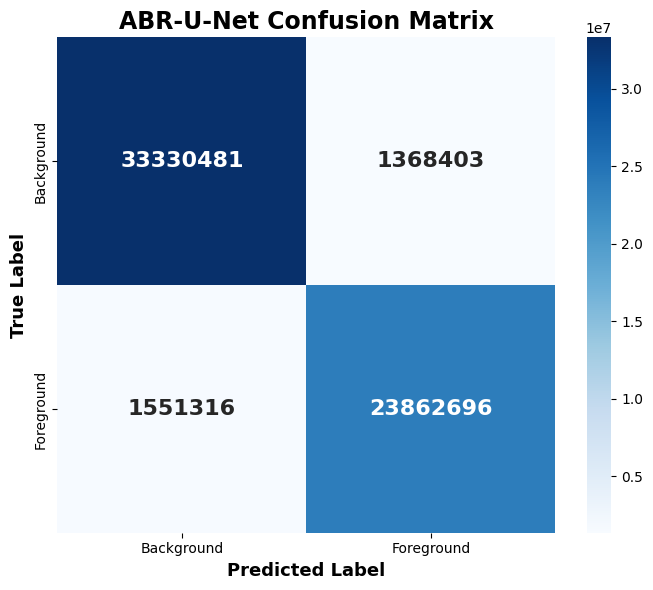

Confusion matrix saved to:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment10_Image_Segmentation/Results/Confusion_Matrices/ABR_UNet_Confusion_Matrix.png


In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# Flatten prediction and target masks
# ------------------------------------------------------------

pred_flat = np.asarray(
    custom_predictions
).astype(np.uint8).reshape(-1)

target_flat = np.asarray(
    custom_targets
).astype(np.uint8).reshape(-1)

# Make sure values are binary
pred_flat = (pred_flat > 0).astype(np.uint8)
target_flat = (target_flat > 0).astype(np.uint8)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    target_flat,
    pred_flat,
    labels=[0, 1]
)

print("ABR-U-Net Confusion Matrix:")
print(cm)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 6)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Background",
        "Foreground"
    ],
    yticklabels=[
        "Background",
        "Foreground"
    ],
    annot_kws={
        "size": 16,
        "weight": "bold"
    }
)

plt.xlabel(
    "Predicted",
    fontsize=13,
    fontweight="bold"
)

plt.ylabel(
    "Actual",
    fontsize=13,
    fontweight="bold"
)

plt.title(
    "ABR-U-Net Confusion Matrix",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

cm_dir = os.path.join(
    RESULTS_DIR,
    "Confusion_Matrices"
)

os.makedirs(
    cm_dir,
    exist_ok=True
)

cm_path = os.path.join(
    cm_dir,
    "ABR_UNet_Confusion_Matrix.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved to:")
print(cm_path)

#Add custom model to comparison

In [ ]:
custom_row = {
    "Model": "ABR-U-Net",
    **custom_metrics,
    "Training Time (min)": custom_training_time / 60
}

results_df = pd.concat(
    [
        results_df,
        pd.DataFrame([custom_row])
    ],
    ignore_index=True
)

results_df.to_csv(
    os.path.join(
        COMPARISON_DIR,
        "FINAL_ALL_MODEL_RESULTS.csv"
    ),
    index=False
)

results_df

,Model,IoU,Dice,Pixel Accuracy,Precision,Recall,F1-score,Mean IoU,Inference Time (sec),Inference Time/Image (ms),Training Time (min)
0,UNet,0.886184,0.939658,0.949729,0.953893,0.925841,0.939658,0.901790,4.203362,1.145642,25.058135
1,UNet++,0.891086,0.942407,0.951912,0.954501,0.930615,0.942407,0.905903,9.846365,2.683665,6.105361
2,FPN,0.883193,0.937974,0.947546,0.937820,0.938129,0.937974,0.898130,5.572166,1.518715,5.103013
3,Attention U-Net,0.888310,0.940852,0.950436,0.949442,0.932415,0.940852,0.903247,6.890768,1.878105,5.503744
4,BASNet,0.785768,0.880033,0.899293,0.886458,0.873702,0.880033,0.813037,8.015625,2.184689,5.356187
5,DeepLabV3+,0.882723,0.937709,0.947595,0.942467,0.932998,0.937709,0.898091,5.444592,1.483944,5.267843
6,SegFormer,0.891352,0.942555,0.951028,0.934921,0.950315,0.942555,0.904746,8.641718,2.355333,5.822925
7,ABR-U-Net,0.890984,0.942349,0.951429,0.945765,0.938958,0.942349,0.905220,7.496175,2.043111,5.761578


#Task 4 - Own mobile-phone images

#Create task-4 folders

In [ ]:
TASK4_IMAGE_DIR = os.path.join(
    TASK4_DIR,
    "Images"
)

TASK4_MASK_DIR = os.path.join(
    TASK4_DIR,
    "Masks"
)

TASK4_RESULT_DIR = os.path.join(
    TASK4_DIR,
    "Results"
)

os.makedirs(
    TASK4_IMAGE_DIR,
    exist_ok=True
)

os.makedirs(
    TASK4_MASK_DIR,
    exist_ok=True
)

os.makedirs(
    TASK4_RESULT_DIR,
    exist_ok=True
)

print("Put your mobile images here:")
print(TASK4_IMAGE_DIR)

print("\nPut your manually created masks here:")
print(TASK4_MASK_DIR)

Put your mobile images here:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment10_Image_Segmentation/Task4_Self_Captured/Images

Put your manually created masks here:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment10_Image_Segmentation/Task4_Self_Captured/Masks


#Task-4 dataset

In [ ]:
class MobilePetDataset(Dataset):

    def __init__(
        self,
        image_dir,
        mask_dir
    ):

        self.image_dir = image_dir
        self.mask_dir = mask_dir

        self.images = sorted([
            f for f in os.listdir(image_dir)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_name = self.images[idx]

        image_path = os.path.join(
            self.image_dir,
            image_name
        )

        base_name = os.path.splitext(
            image_name
        )[0]

        mask_name = (
            base_name +
            "_mask.png"
        )

        mask_path = os.path.join(
            self.mask_dir,
            mask_name
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        mask = Image.open(
            mask_path
        ).convert("L")

        image, mask = SegmentationTransform(
            train=False
        )(image, mask)

        return image, mask, image_name

#Load mobile dataset

In [ ]:
mobile_dataset = MobilePetDataset(
    TASK4_IMAGE_DIR,
    TASK4_MASK_DIR
)

mobile_loader = DataLoader(
    mobile_dataset,
    batch_size=1,
    shuffle=False
)

print(
    "Mobile images:",
    len(mobile_dataset)
)

Mobile images: 5


#Sample images from the mobile dataset

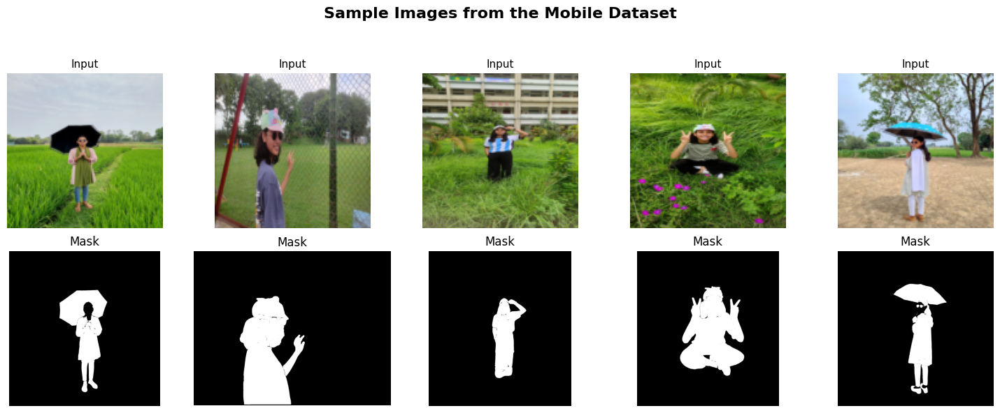

File successfully saved to Drive: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment10_Image_Segmentation/Task4_Self_Captured/Results/mobile_dataset_samples.png


In [ ]:
# Set dataset and display parameters
num_samples = min(5, len(mobile_dataset))

plt.figure(figsize=(15, 6))

# Add an overall figure title
plt.suptitle("Sample Images from the Mobile Dataset", fontsize=16, fontweight="bold")

# Iterate over the mobile loader to collect samples
for i, (images, masks, names) in enumerate(mobile_loader):
    if i >= num_samples:
        break

    # ----------------------------------------------------
    # Denormalize Input Image
    # ----------------------------------------------------
    image = images[0].permute(1, 2, 0).numpy()
    image = image * np.array([0.229, 0.224, 0.225])
    image = image + np.array([0.485, 0.456, 0.406])
    image = np.clip(image, 0, 1)

    # Plot Input Image (Top Row)
    plt.subplot(2, num_samples, i + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Input", fontsize=11)

    # ----------------------------------------------------
    # Load and Binarize Ground Truth Mask
    # ----------------------------------------------------
    base_name = os.path.splitext(names[0])[0]

    # Try finding mask file directly from disk to prevent DataLoader tensor scaling issues
    mask_filename = base_name.replace("Image", "Mask") + ".png"
    mask_path = os.path.join(TASK4_MASK_DIR, mask_filename)

    if not os.path.exists(mask_path):
        mask_filename = f"{base_name}_mask.png"
        mask_path = os.path.join(TASK4_MASK_DIR, mask_filename)

    if os.path.exists(mask_path):
        gt_img = Image.open(mask_path).convert("L")
        gt_np = np.array(gt_img)
        mask_display = (gt_np > 0).astype(np.float32)
    else:
        # Fallback to mask tensor from dataloader if file path isn't matched
        gt_tensor = masks[0].squeeze().cpu()
        gt_np = gt_tensor.numpy()
        mask_display = (gt_np > (gt_np.max() * 0.1)).astype(np.float32) if gt_np.max() > 0 else gt_np

    # Plot Mask (Bottom Row)
    plt.subplot(2, num_samples, i + 1 + num_samples)
    plt.imshow(mask_display, cmap="gray", vmin=0, vmax=1)
    plt.axis("off")
    plt.title("Mask", fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.93])

# Save figure
save_path = os.path.join(TASK4_RESULT_DIR, "mobile_dataset_samples.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"File successfully saved to Drive: {save_path}")

#Task-4 evaluation

In [ ]:
def evaluate_mobile_model(
    model,
    model_name
):

    model.eval()

    results = []

    with torch.no_grad():

        for images, masks, names in mobile_loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            outputs = model(images)

            predictions = (
                torch.sigmoid(outputs) >= 0.5
            ).float()

            pred = (
                predictions[0, 0]
                .cpu()
                .numpy()
                .astype(np.uint8)
            )

            target = (
                masks[0, 0]
                .cpu()
                .numpy()
                .astype(np.uint8)
            )

            metrics = calculate_metrics(
                pred,
                target
            )

            metrics["Image"] = names[0]
            metrics["Model"] = model_name

            results.append(metrics)

    return pd.DataFrame(results)

#Evaluate all models on mobile images

In [ ]:
mobile_results = []

# Standard models
for name in MODEL_NAMES:

    print("Processing:", name)

    model = create_model(name)

    model_path = os.path.join(
        MODEL_DIR,
        name.replace(" ", "_"),
        "best_model.pth"
    )

    model.load_state_dict(
        torch.load(
            model_path,
            map_location=DEVICE
        )
    )

    df = evaluate_mobile_model(
        model,
        name
    )

    mobile_results.append(df)

    del model
    torch.cuda.empty_cache()


# Custom model
custom_model = ABRUNet().to(DEVICE)

custom_model.load_state_dict(
    torch.load(
        os.path.join(
            MODEL_DIR,
            "ABR_UNet_best.pth"
        ),
        map_location=DEVICE
    )
)

df = evaluate_mobile_model(
    custom_model,
    "ABR-U-Net"
)

mobile_results.append(df)

mobile_results_df = pd.concat(
    mobile_results,
    ignore_index=True
)

mobile_results_df.to_csv(
    os.path.join(
        TASK4_RESULT_DIR,
        "mobile_image_results.csv"
    ),
    index=False
)

mobile_results_df

Processing: UNet
Processing: UNet++
Processing: FPN
Processing: Attention U-Net
Processing: BASNet
Processing: DeepLabV3+


[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


Processing: SegFormer


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.batch_norm.running_mean                     

,IoU,Dice,Pixel Accuracy,Precision,Recall,F1-score,Mean IoU,Image,Model
0,0.089539,0.164361,0.089539,1.0,0.089539,0.164361,0.044769,Image1.jpg,UNet
1,0.070679,0.132026,0.070679,1.0,0.070679,0.132026,0.035339,Image2.jpg,UNet
2,0.014709,0.028992,0.014709,1.0,0.014709,0.028992,0.007355,Image3.jpg,UNet
3,0.080627,0.149223,0.080627,1.0,0.080627,0.149223,0.040314,Image4.jpg,UNet
4,0.050720,0.096544,0.050720,1.0,0.050720,0.096544,0.025360,Image5.jpg,UNet
5,0.050293,0.095769,0.050293,1.0,0.050293,0.095769,0.025146,Image1.jpg,UNet++
6,0.028687,0.055773,0.028687,1.0,0.028687,0.055773,0.014343,Image2.jpg,UNet++
7,0.023010,0.044985,0.023010,1.0,0.023010,0.044985,0.011505,Image3.jpg,UNet++
8,0.120544,0.215153,0.120544,1.0,0.120544,0.215153,0.060272,Image4.jpg,UNet++
9,0.079895,0.147968,0.079895,1.0,0.079895,0.147968,0.039948,Image5.jpg,UNet++


#Display task-4 results

In [ ]:
def display_mobile_predictions(
    model,
    model_name
):

    model.eval()

    # Collect up to 5 samples for the grid display
    samples = []

    with torch.no_grad():

        for images, masks, names in mobile_loader:

            images = images.to(DEVICE)

            outputs = model(images)

            # Handle models returning dict outputs (e.g., DeepLabV3)
            if isinstance(outputs, dict):
                outputs = outputs['out']

            prediction = (
                torch.sigmoid(outputs) >= 0.5
            ).float()

            for i in range(images.size(0)):
                if len(samples) >= 5:
                    break

                # 1. Denormalize input image
                image = images[i].cpu().permute(
                    1, 2, 0
                ).numpy()

                image = image * np.array(
                    [0.229, 0.224, 0.225]
                )

                image = image + np.array(
                    [0.485, 0.456, 0.406]
                )

                image = np.clip(
                    image,
                    0,
                    1
                )

                # 2. LOAD MASK DIRECTLY FROM DISK TO BYPASS DATALOADER CORRUPTION
                filename = names[i]
                base_name = os.path.splitext(filename)[0]

                # Check for both Mask1.png and Image1_mask.png naming conventions
                mask_filename = base_name.replace("Image", "Mask") + ".png"
                mask_path = os.path.join(TASK4_MASK_DIR, mask_filename)

                if not os.path.exists(mask_path):
                    mask_filename = f"{base_name}_mask.png"
                    mask_path = os.path.join(TASK4_MASK_DIR, mask_filename)

                if os.path.exists(mask_path):
                    # Open raw mask image and convert to numpy array
                    gt_img = Image.open(mask_path).convert("L")
                    gt_np = np.array(gt_img)
                    # Binarize directly: Any pixel > 0 becomes 1.0 (White)
                    ground_truth = (gt_np > 0).astype(np.float32)
                else:
                    # Fallback to loader mask if file path not found
                    gt_tensor = masks[i].cpu().squeeze()
                    ground_truth = (gt_tensor.numpy() > 0).astype(np.float32)

                # 3. Extract prediction mask to 2D numpy array
                pred_tensor = prediction[i].cpu().squeeze()
                pred = (pred_tensor.numpy() > 0.5).astype(np.float32)

                samples.append((image, ground_truth, pred, names[i]))

            if len(samples) >= 5:
                break

    num_samples = len(samples)

    # Create figure and add main model title at the top
    fig, axes = plt.subplots(3, num_samples, figsize=(4 * num_samples, 10))
    fig.suptitle(f"Model Segmentation Results: {model_name}", fontsize=18, fontweight="bold", y=0.98)

    # Handle indexing for single image edge cases
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=1)

    for idx, (image, ground_truth, pred, name) in enumerate(samples):
        file_label = os.path.splitext(name)[0]

        # Row 1: Input Image
        axes[0, idx].imshow(image)
        axes[0, idx].set_title(f"Input", fontsize=11, fontweight="bold")
        if idx == 0:
            axes[0, idx].set_ylabel("Input Image", fontsize=13, fontweight="bold")
        axes[0, idx].axis("off")

        # Row 2: Ground Truth (Forced display scaling vmin=0, vmax=1)
        axes[1, idx].imshow(
            ground_truth,
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[1, idx].set_title(f"Ground Truth", fontsize=11, fontweight="bold")
        if idx == 0:
            axes[1, idx].set_ylabel("Ground Truth", fontsize=13, fontweight="bold")
        axes[1, idx].axis("off")

        # Row 3: Prediction
        axes[2, idx].imshow(
            pred,
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[2, idx].set_title(f"Prediction", fontsize=11, fontweight="bold")
        if idx == 0:
            axes[2, idx].set_ylabel(f"{model_name}\nPrediction", fontsize=13, fontweight="bold")
        axes[2, idx].axis("off")

    plt.tight_layout()

    save_name = (
        model_name.replace(" ", "_")
        + "_grid_results.png"
    )

    plt.savefig(
        os.path.join(
            TASK4_RESULT_DIR,
            save_name
        ),
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

#Run task-4 visualization

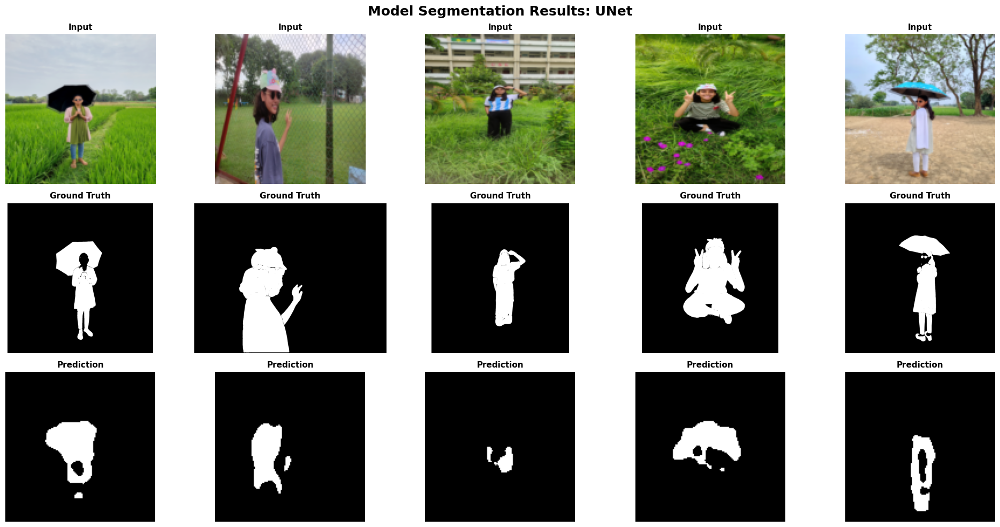

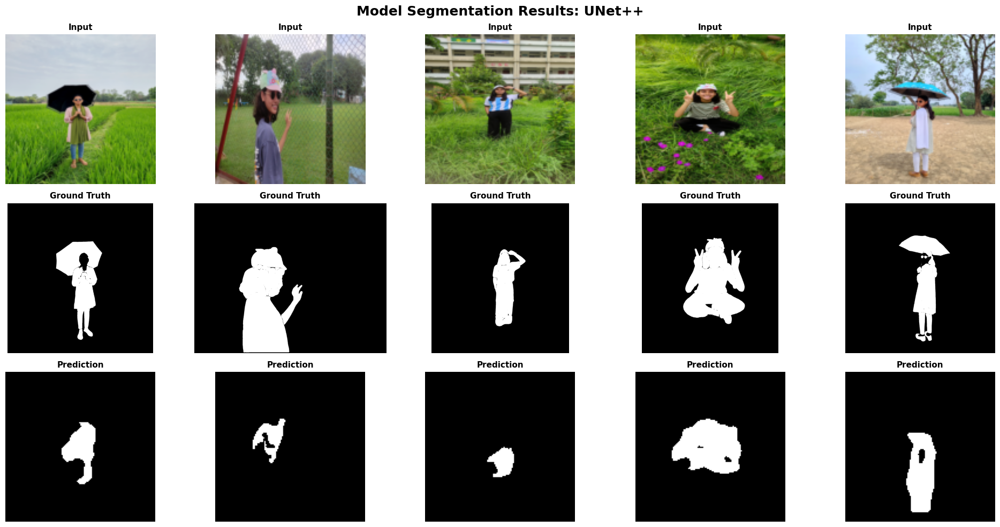

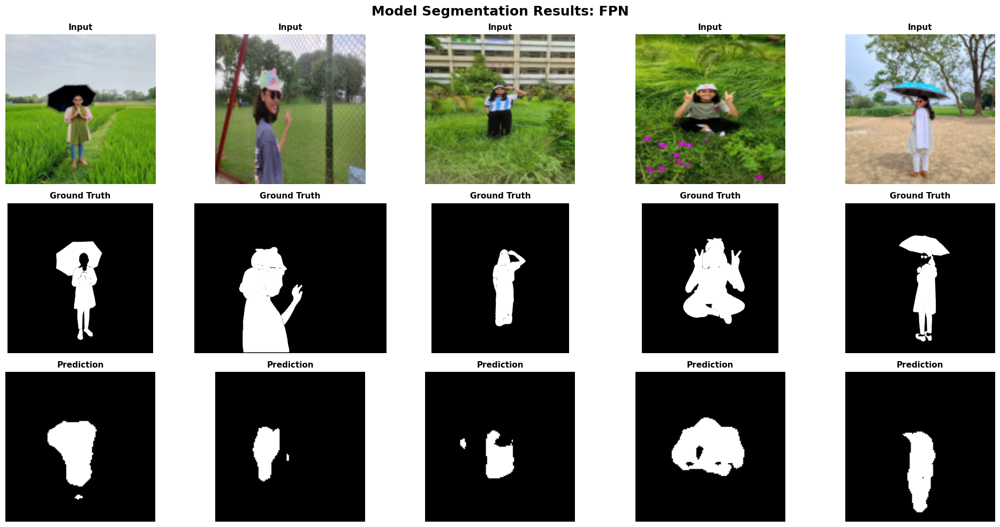

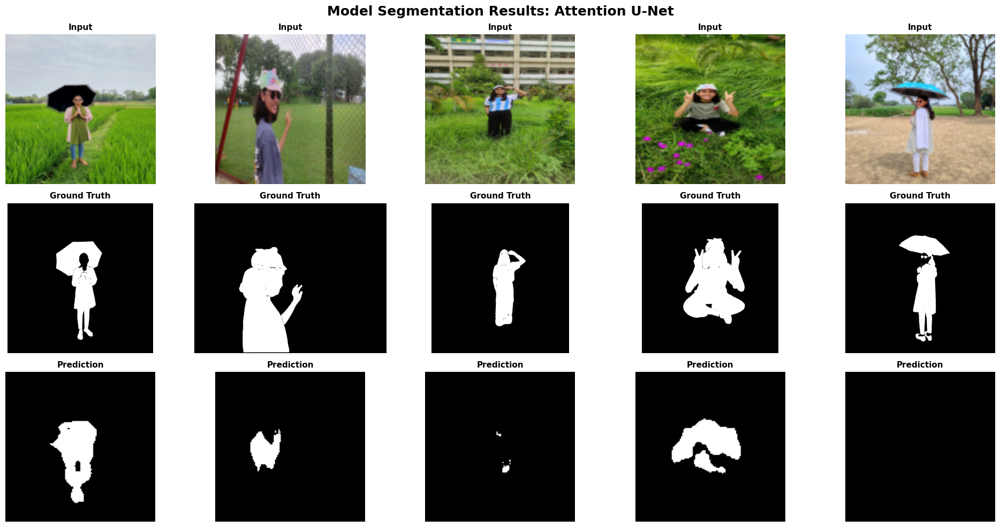

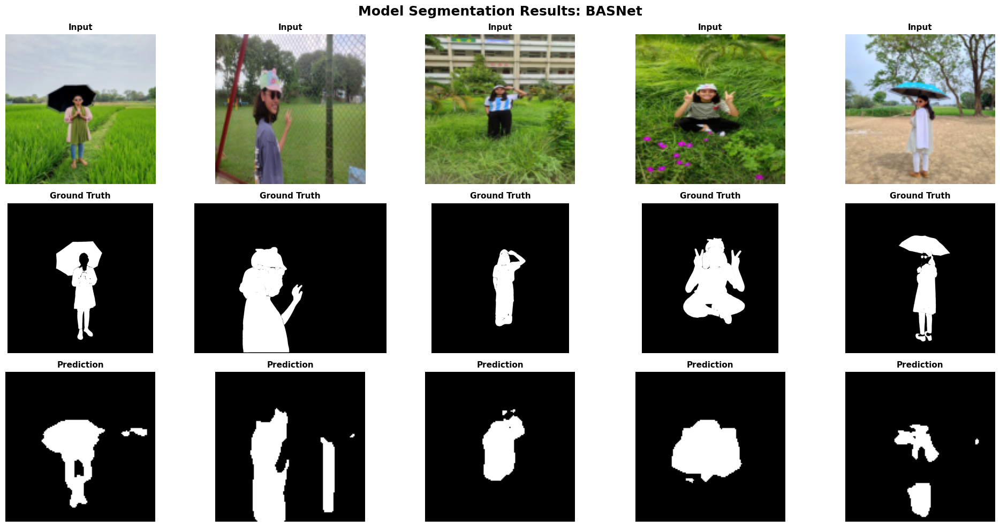

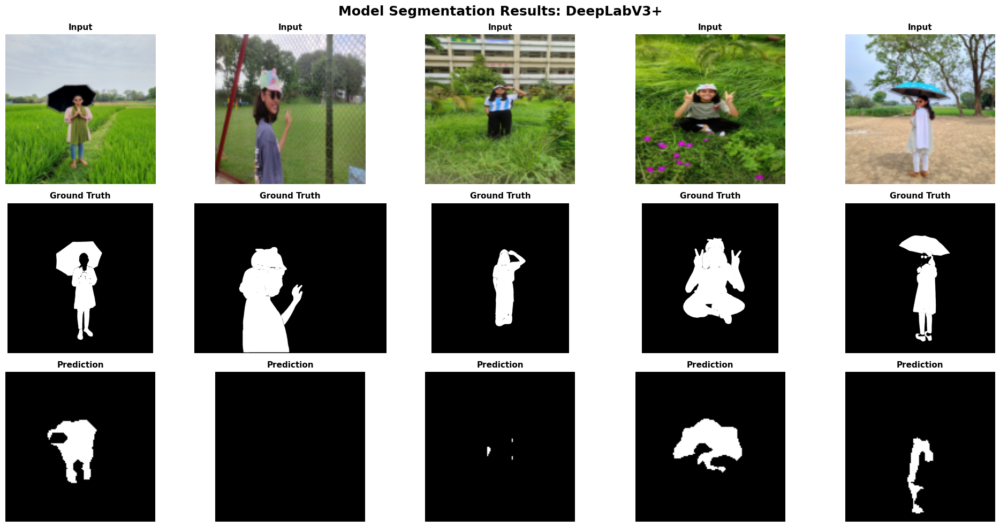

[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.batch_norm.running_mean                     

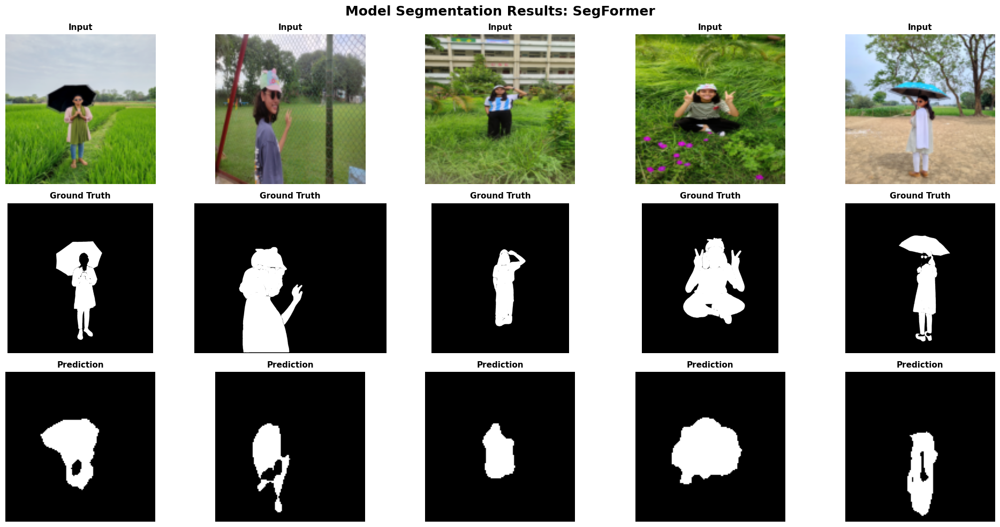

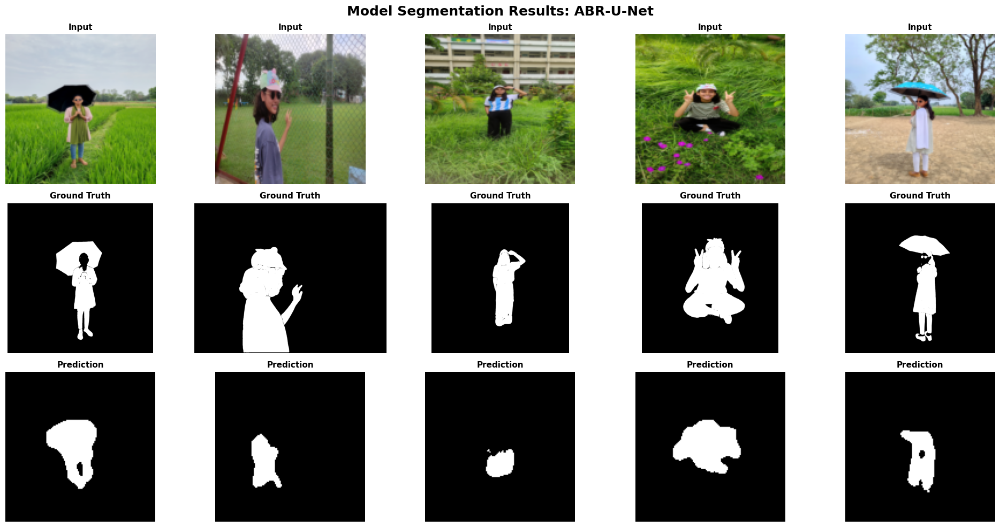

In [ ]:
for name in MODEL_NAMES:

    model = create_model(name)

    model_path = os.path.join(
        MODEL_DIR,
        name.replace(" ", "_"),
        "best_model.pth"
    )

    model.load_state_dict(
        torch.load(
            model_path,
            map_location=DEVICE
        )
    )

    display_mobile_predictions(
        model,
        name
    )

    del model
    torch.cuda.empty_cache()


display_mobile_predictions(
    custom_model,
    "ABR-U-Net"
)